<a href="https://colab.research.google.com/github/mujtaba-mohiyuddin/ucb-traffic-sign-recognition/blob/main/UCB_20260920_NLP_Assignment3_Preliminary.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Assignment 3 — N-gram Language Models and Cosine Similarity

**Datasets:**
- **Part A corpus:** NLTK Gutenberg corpus (https://www.nltk.org/book/ch02.html)
- **Part B corpus:** BBC News dataset (http://mlg.ucd.ie/datasets/bbc.html), with `fetch_20newsgroups` as a fallback, and a small embedded mini-corpus as a final fallback

This section covers the **preliminary steps for Part A**: loading the corpus, splitting into train/held-out, tokenizing, and building the vocabulary with the `<unk>` threshold — everything the n-gram counting and smoothing work will depend on.

## 0. Setup

In [43]:
import re
import math
import random
from collections import Counter, defaultdict

import numpy as np
import matplotlib.pyplot as plt

import nltk
nltk.download('gutenberg')
nltk.download('punkt')
nltk.download('punkt_tab')

from nltk.corpus import gutenberg

random.seed(42)
np.random.seed(42)

[nltk_data] Downloading package gutenberg to /root/nltk_data...
[nltk_data]   Package gutenberg is already up-to-date!
[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


In [44]:
print("Available Gutenberg files:", gutenberg.fileids())

BOOK_ID = 'austen-emma.txt'  # <-- change this to use a different single book

raw_text = gutenberg.raw(BOOK_ID)
print(f"\nUsing book: {BOOK_ID}")
print(f"Total characters: {len(raw_text):,}")
print(f"Total raw whitespace-split words: {len(raw_text.split()):,}")
print("\nSample:\n", raw_text[:500])

Available Gutenberg files: ['austen-emma.txt', 'austen-persuasion.txt', 'austen-sense.txt', 'bible-kjv.txt', 'blake-poems.txt', 'bryant-stories.txt', 'burgess-busterbrown.txt', 'carroll-alice.txt', 'chesterton-ball.txt', 'chesterton-brown.txt', 'chesterton-thursday.txt', 'edgeworth-parents.txt', 'melville-moby_dick.txt', 'milton-paradise.txt', 'shakespeare-caesar.txt', 'shakespeare-hamlet.txt', 'shakespeare-macbeth.txt', 'whitman-leaves.txt']

Using book: austen-emma.txt
Total characters: 887,071
Total raw whitespace-split words: 158,167

Sample:
 [Emma by Jane Austen 1816]

VOLUME I

CHAPTER I


Emma Woodhouse, handsome, clever, and rich, with a comfortable home
and happy disposition, seemed to unite some of the best blessings
of existence; and had lived nearly twenty-one years in the world
with very little to distress or vex her.

She was the youngest of the two daughters of a most affectionate,
indulgent father; and had, in consequence of her sister's marriage,
been mistress of his 

In [45]:

raw_sentences = [" ".join(sent) for sent in gutenberg.sents(BOOK_ID)]

print(f"Total sentences (NLTK pre-split): {len(raw_sentences):,}")
print("Example:", raw_sentences[0])

Total sentences (NLTK pre-split): 7,752
Example: [ Emma by Jane Austen 1816 ]


In [46]:
#Train / Held-out Split
sentences = raw_sentences[:]  # from Section 2
random.shuffle(sentences)

HELD_OUT_FRACTION = 0.1
split_idx = int(len(sentences) * (1 - HELD_OUT_FRACTION))

train_sentences = sentences[:split_idx]
heldout_sentences = sentences[split_idx:]

print(f"Train sentences:    {len(train_sentences):,}")
print(f"Held-out sentences: {len(heldout_sentences):,}")

Train sentences:    6,976
Held-out sentences: 776


In [47]:
TOKEN_RE = re.compile(r"[a-z]+(?:'[a-z]+)?|[0-9]+|[.,!?;:]")

def tokenize(sentence: str):
    return TOKEN_RE.findall(sentence.lower())

sample = train_sentences[0]
print("RAW:   ", sample)
print("TOKENS:", tokenize(sample))

RAW:    I think they judge wisely .
TOKENS: ['i', 'think', 'they', 'judge', 'wisely', '.']


In [48]:
train_tokenized = [tokenize(s) for s in train_sentences]
heldout_tokenized = [tokenize(s) for s in heldout_sentences]

# Drop any sentences that tokenized to nothing (e.g., blank lines)
train_tokenized = [s for s in train_tokenized if s]
heldout_tokenized = [s for s in heldout_tokenized if s]

train_word_count = sum(len(s) for s in train_tokenized)
heldout_word_count = sum(len(s) for s in heldout_tokenized)

print(f"Training set word count:   {train_word_count:,}")
print(f"Held-out set word count:   {heldout_word_count:,}")

Training set word count:   168,021
Held-out set word count:   19,077


In [49]:
#Vocabulary with <unk> Threshold

def build_vocab(tokenized_sentences, k: int):
    word_counts = Counter(tok for sent in tokenized_sentences for tok in sent)
    vocab = {w for w, c in word_counts.items() if c >= k}
    vocab.add('<unk>')
    vocab.add('<s>')
    vocab.add('</s>')
    return vocab, word_counts

for k in [1, 2, 3, 5, 10]:
    vocab_k, _ = build_vocab(train_tokenized, k)
    print(f"k={k:2d}: vocabulary size = {len(vocab_k):,}")

k= 1: vocabulary size = 6,848
k= 2: vocabulary size = 4,166
k= 3: vocabulary size = 3,177
k= 5: vocabulary size = 2,204
k=10: vocabulary size = 1,322


In [50]:
# Final choice of k -- justify this value in your write-up using the table above
K_THRESHOLD = 2  # lower threshold appropriate for a single-book, ~170K-word training set

vocab, train_word_counts = build_vocab(train_tokenized, K_THRESHOLD)
print(f"Final vocabulary size (k={K_THRESHOLD}): {len(vocab):,}")

def apply_unk(tokenized_sentences, vocab):
    return [[tok if tok in vocab else '<unk>' for tok in sent] for sent in tokenized_sentences]

train_unk = apply_unk(train_tokenized, vocab)
heldout_unk = apply_unk(heldout_tokenized, vocab)

total_tokens = sum(len(s) for s in train_unk)
unk_tokens = sum(tok == '<unk>' for sent in train_unk for tok in sent)
print(f"Fraction of training tokens mapped to <unk>: {unk_tokens/total_tokens:.2%}")

Final vocabulary size (k=2): 4,166
Fraction of training tokens mapped to <unk>: 1.60%


In [51]:
#Sentence Boundary Markers
def add_boundaries(tokenized_sentences):
    return [['<s>'] + sent + ['</s>'] for sent in tokenized_sentences]

train_final = add_boundaries(train_unk)
heldout_final = add_boundaries(heldout_unk)

print("Example prepared training sentence:")
print(train_final[0])
print(f"\nTotal prepared training sentences: {len(train_final):,}")
print(f"Total prepared held-out sentences:  {len(heldout_final):,}")

Example prepared training sentence:
['<s>', 'i', 'think', 'they', 'judge', '<unk>', '.', '</s>']

Total prepared training sentences: 6,970
Total prepared held-out sentences:  776


In [52]:
#preview — BBC News Loader (with fallback chain)
import os
import urllib.request
import zipfile
import io

def load_bbc_corpus():
    """Try to load the real BBC News dataset; fall back gracefully if unavailable."""
    bbc_url = "http://mlg.ucd.ie/files/datasets/bbc-fulltext.zip"
    extract_dir = "/content/bbc_data" if os.path.exists("/content") else "bbc_data"

    try:
        print("Attempting to download BBC News dataset...")
        resp = urllib.request.urlopen(bbc_url, timeout=15)
        with zipfile.ZipFile(io.BytesIO(resp.read())) as z:
            z.extractall(extract_dir)

        docs, labels = [], []
        bbc_root = os.path.join(extract_dir, "bbc")
        for category in os.listdir(bbc_root):
            cat_dir = os.path.join(bbc_root, category)
            if not os.path.isdir(cat_dir):
                continue
            for fname in os.listdir(cat_dir):
                fpath = os.path.join(cat_dir, fname)
                with open(fpath, "r", encoding="latin-1") as f:
                    docs.append(f.read())
                    labels.append(category)

        print(f"Loaded BBC News dataset: {len(docs)} articles across {len(set(labels))} categories.")
        return docs, labels, "bbc"

    except Exception as e:
        print(f"BBC download failed ({e}). Falling back to fetch_20newsgroups...")

    try:
        from sklearn.datasets import fetch_20newsgroups
        data = fetch_20newsgroups(subset='train', remove=('headers', 'footers', 'quotes'))
        print(f"Loaded 20 Newsgroups fallback: {len(data.data)} documents.")
        return data.data, [data.target_names[t] for t in data.target], "20newsgroups"

    except Exception as e:
        print(f"20 Newsgroups fallback failed ({e}). Using embedded mini-corpus...")

    # Final fallback: tiny embedded mini-corpus so the notebook always runs
    mini_docs = [
        "The stock market rallied today as tech shares surged on strong earnings.",
        "The central bank raised interest rates to combat rising inflation.",
        "The football team won the championship after a thrilling final match.",
        "A new smartphone was unveiled featuring an improved camera and battery life.",
        "Scientists discovered a new exoplanet that may support liquid water.",
        "The election results sparked debate among political analysts nationwide.",
    ]
    mini_labels = ["business", "business", "sport", "tech", "science", "politics"]
    print(f"Loaded embedded mini-corpus: {len(mini_docs)} documents.")
    return mini_docs, mini_labels, "mini"

bbc_docs, bbc_labels, bbc_source = load_bbc_corpus()
print(f"\nSource used: {bbc_source}")
print(f"Sample document:\n{bbc_docs[0][:300]}")

Attempting to download BBC News dataset...
BBC download failed (<urlopen error timed out>). Falling back to fetch_20newsgroups...
Loaded 20 Newsgroups fallback: 11314 documents.

Source used: 20newsgroups
Sample document:
I was wondering if anyone out there could enlighten me on this car I saw
the other day. It was a 2-door sports car, looked to be from the late 60s/
early 70s. It was called a Bricklin. The doors were really small. In addition,
the front bumper was separate from the rest of the body. This is 
all I k


In [53]:
#Unigram & Bigram Count Tables

unigram_counts = Counter()
bigram_counts = Counter()

for sent in train_final:
    unigram_counts.update(sent)
    bigram_counts.update(zip(sent[:-1], sent[1:]))

vocab_size = len(vocab)
total_unigrams = sum(unigram_counts.values())
total_bigrams = sum(bigram_counts.values())

print(f"Vocabulary size:         {vocab_size:,}")
print(f"Total unigram tokens:    {total_unigrams:,}")
print(f"Distinct bigram types:   {len(bigram_counts):,}")
print(f"Total bigram tokens:     {total_bigrams:,}")

print("\nTop 10 unigrams:", unigram_counts.most_common(10))
print("\nTop 10 bigrams: ", bigram_counts.most_common(10))

Vocabulary size:         4,166
Total unigram tokens:    181,961
Distinct bigram types:   52,884
Total bigram tokens:     174,991

Top 10 unigrams: [(',', 10833), ('.', 7968), ('<s>', 6970), ('</s>', 6970), ('the', 4704), ('to', 4683), ('and', 4387), ('of', 3858), ('i', 2869), ('a', 2798)]

Top 10 bigrams:  [(('.', '</s>'), 5709), ((',', 'and'), 1711), (('mr', '.'), 1039), ((';', 'and'), 815), (('<s>', 'i'), 799), (('!', '</s>'), 655), (('mrs', '.'), 620), ((',', 'i'), 574), (('to', 'be'), 550), (('of', 'the'), 509)]


In [54]:
#Probability Estimates
def unigram_prob_mle(word, unigram_counts=unigram_counts, total=total_unigrams):
    return unigram_counts.get(word, 0) / total

def unigram_prob_laplace(word, unigram_counts=unigram_counts, total=total_unigrams, V=vocab_size):
    return (unigram_counts.get(word, 0) + 1) / (total + V)

def bigram_prob_mle(w_prev, w, unigram_counts=unigram_counts, bigram_counts=bigram_counts):
    denom = unigram_counts.get(w_prev, 0)
    if denom == 0:
        return 0.0
    return bigram_counts.get((w_prev, w), 0) / denom

def bigram_prob_laplace(w_prev, w, unigram_counts=unigram_counts, bigram_counts=bigram_counts, V=vocab_size):
    denom = unigram_counts.get(w_prev, 0) + V
    return (bigram_counts.get((w_prev, w), 0) + 1) / denom

def bigram_prob_addk(w_prev, w, k, unigram_counts=unigram_counts, bigram_counts=bigram_counts, V=vocab_size):
    denom = unigram_counts.get(w_prev, 0) + k * V
    return (bigram_counts.get((w_prev, w), 0) + k) / denom

# Quick sanity checks
w1, w2 = 'the', 'king'
print(f"Unigram MLE P('{w1}')          = {unigram_prob_mle(w1):.6f}")
print(f"Unigram Laplace P('{w1}')      = {unigram_prob_laplace(w1):.6f}")
print(f"Bigram MLE P('{w2}' | '{w1}')     = {bigram_prob_mle(w1, w2):.6f}")
print(f"Bigram Laplace P('{w2}' | '{w1}') = {bigram_prob_laplace(w1, w2):.6f}")
print(f"Bigram add-0.1 P('{w2}' | '{w1}') = {bigram_prob_addk(w1, w2, 0.1):.6f}")

Unigram MLE P('the')          = 0.025852
Unigram Laplace P('the')      = 0.025278
Bigram MLE P('king' | 'the')     = 0.000213
Bigram Laplace P('king' | 'the') = 0.000225
Bigram add-0.1 P('king' | 'the') = 0.000215


In [55]:
#Zero-Probability Demonstration

def find_sentence_with_unseen_bigram(sentences, bigram_counts):
    for sent in sentences:
        bigrams = list(zip(sent[:-1], sent[1:]))
        if any(bigram_counts.get(bg, 0) == 0 for bg in bigrams):
            return sent, bigrams
    return None, None

demo_sentence, demo_bigrams = find_sentence_with_unseen_bigram(heldout_final, bigram_counts)

print("Held-out sentence with an unseen bigram:")
print(" ".join(demo_sentence))
print()

unseen = [bg for bg in demo_bigrams if bigram_counts.get(bg, 0) == 0]
print(f"Unseen bigram(s) in this sentence: {unseen}")

# MLE probability of the whole sentence (product of bigram probs)
mle_prob = 1.0
for w_prev, w in demo_bigrams:
    mle_prob *= bigram_prob_mle(w_prev, w)

laplace_prob = 1.0
for w_prev, w in demo_bigrams:
    laplace_prob *= bigram_prob_laplace(w_prev, w)

print(f"\nBigram MLE probability of full sentence:     {mle_prob}")
print(f"Bigram Laplace probability of full sentence: {laplace_prob}")
print("\n>>> MLE assigns exactly zero probability to this ordinary sentence.")
print(">>> Laplace smoothing assigns it a small but non-zero probability, fixing the sparsity problem.")

Held-out sentence with an unseen bigram:
<s> cole was saying the other day she wanted something from kingston . </s>

Unseen bigram(s) in this sentence: [('saying', 'the'), ('wanted', 'something'), ('something', 'from'), ('from', 'kingston')]

Bigram MLE probability of full sentence:     0.0
Bigram Laplace probability of full sentence: 3.992584632833685e-39

>>> MLE assigns exactly zero probability to this ordinary sentence.
>>> Laplace smoothing assigns it a small but non-zero probability, fixing the sparsity problem.


In [56]:
##sentence_logprob() and perplexity()

LOG_ZERO = float('-inf')

def sentence_logprob_unigram(sentence, prob_fn):
    """sentence: list of tokens including <s>/</s>. Unigram model scores every token including boundaries."""
    logprob = 0.0
    for w in sentence:
        p = prob_fn(w)
        if p <= 0:
            return LOG_ZERO
        logprob += math.log(p)
    return logprob

def sentence_logprob_bigram(sentence, prob_fn):
    """prob_fn(w_prev, w) -> probability. Scores each bigram (w_{i-1}, w_i) in the sentence."""
    logprob = 0.0
    for w_prev, w in zip(sentence[:-1], sentence[1:]):
        p = prob_fn(w_prev, w)
        if p <= 0:
            return LOG_ZERO
        logprob += math.log(p)
    return logprob

def perplexity(sentences, logprob_fn, prob_fn, count_boundary_tokens=False):
    """
    sentences: list of tokenized (boundary-marked) sentences
    logprob_fn: sentence_logprob_unigram or sentence_logprob_bigram
    prob_fn: the underlying word/bigram probability function
    count_boundary_tokens: whether <s> counts toward N (</s> always counts as an end-of-sequence event)
    """
    total_logprob = 0.0
    total_tokens = 0

    for sent in sentences:
        lp = logprob_fn(sent, prob_fn)
        if lp == LOG_ZERO:
            return float('inf')  # undefined / infinite perplexity if any sentence has zero probability
        total_logprob += lp
        if logprob_fn is sentence_logprob_unigram:
            n = len(sent) if count_boundary_tokens else len(sent) - (1 if sent[0] == '<s>' else 0)
        else:
            n = len(sent) - 1  # number of bigrams scored
        total_tokens += n

    avg_logprob = total_logprob / total_tokens
    return math.exp(-avg_logprob)

print("Perplexity functions defined.")

Perplexity functions defined.


In [58]:
##Perplexity Sweep

ppl_unigram_mle = perplexity(heldout_final, sentence_logprob_unigram, unigram_prob_mle)
ppl_unigram_laplace = perplexity(heldout_final, sentence_logprob_unigram, unigram_prob_laplace)
ppl_bigram_laplace = perplexity(heldout_final, sentence_logprob_bigram, bigram_prob_laplace)

print(f"Unigram MLE perplexity:      {ppl_unigram_mle}")
print(f"Unigram Laplace perplexity: {ppl_unigram_laplace:.2f}")
print(f"Bigram Laplace perplexity:  {ppl_bigram_laplace:.2f}")

Unigram MLE perplexity:      359.43589029487987
Unigram Laplace perplexity: 361.11
Bigram Laplace perplexity:  375.65


In [59]:
k_values = [0.01, 0.05, 0.1, 0.2, 0.3, 0.5, 0.7, 1.0]
addk_perplexities = []

for k in k_values:
    prob_fn = lambda w_prev, w, k=k: bigram_prob_addk(w_prev, w, k)
    ppl = perplexity(heldout_final, sentence_logprob_bigram, prob_fn)
    addk_perplexities.append(ppl)
    print(f"k={k:>5}: perplexity = {ppl:.2f}")

best_idx = int(np.argmin(addk_perplexities))
best_k = k_values[best_idx]
print(f"\nOptimal k (lowest held-out perplexity): {best_k}")

k= 0.01: perplexity = 130.92
k= 0.05: perplexity = 146.40
k=  0.1: perplexity = 166.58
k=  0.2: perplexity = 200.27
k=  0.3: perplexity = 228.87
k=  0.5: perplexity = 277.78
k=  0.7: perplexity = 320.03
k=  1.0: perplexity = 375.65

Optimal k (lowest held-out perplexity): 0.01


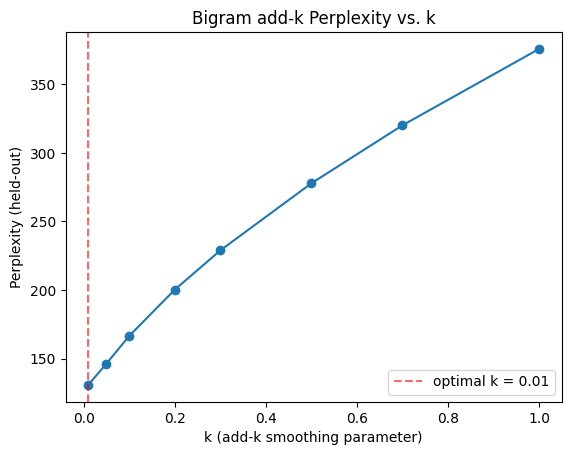

In [60]:
plt.figure()
plt.plot(k_values, addk_perplexities, marker='o')
plt.axvline(best_k, color='red', linestyle='--', alpha=0.6, label=f'optimal k = {best_k}')
plt.xlabel('k (add-k smoothing parameter)')
plt.ylabel('Perplexity (held-out)')
plt.title('Bigram add-k Perplexity vs. k')
plt.legend()
plt.show()

In [61]:
##Linear Interpolation

# Carve a dev split out of the training sentences for tuning lambda
random.shuffle(train_final)
dev_split_idx = int(len(train_final) * 0.95)
train_for_counts = train_final[:dev_split_idx]
dev_sentences = train_final[dev_split_idx:]

# Recount on the reduced training set used for interpolation tuning
# (kept separate from the main unigram_counts/bigram_counts used elsewhere to avoid leakage)
tune_unigram_counts = Counter()
tune_bigram_counts = Counter()
for sent in train_for_counts:
    tune_unigram_counts.update(sent)
    tune_bigram_counts.update(zip(sent[:-1], sent[1:]))
tune_total_unigrams = sum(tune_unigram_counts.values())

def interp_prob(w_prev, w, lam, k=best_k):
    p_bigram = bigram_prob_addk(w_prev, w, k, unigram_counts=tune_unigram_counts,
                                 bigram_counts=tune_bigram_counts)
    p_unigram = unigram_prob_laplace(w, unigram_counts=tune_unigram_counts,
                                      total=tune_total_unigrams)
    return lam * p_bigram + (1 - lam) * p_unigram

lambdas = np.arange(0.1, 1.0, 0.1)
lambda_perplexities = []

for lam in lambdas:
    prob_fn = lambda w_prev, w, lam=lam: interp_prob(w_prev, w, lam)
    ppl = perplexity(dev_sentences, sentence_logprob_bigram, prob_fn)
    lambda_perplexities.append(ppl)
    print(f"lambda={lam:.1f}: dev perplexity = {ppl:.2f}")

best_lambda = lambdas[int(np.argmin(lambda_perplexities))]
print(f"\nBest lambda on dev split: {best_lambda:.1f}")

lambda=0.1: dev perplexity = 221.96
lambda=0.2: dev perplexity = 182.43
lambda=0.3: dev perplexity = 160.24
lambda=0.4: dev perplexity = 145.98
lambda=0.5: dev perplexity = 136.38
lambda=0.6: dev perplexity = 130.03
lambda=0.7: dev perplexity = 126.41
lambda=0.8: dev perplexity = 125.71
lambda=0.9: dev perplexity = 129.71

Best lambda on dev split: 0.8


In [62]:
# Evaluate the tuned interpolation model on the actual held-out set, compare to best add-k bigram model
interp_prob_fn = lambda w_prev, w: interp_prob(w_prev, w, best_lambda)
ppl_interp_heldout = perplexity(heldout_final, sentence_logprob_bigram, interp_prob_fn)

best_addk_prob_fn = lambda w_prev, w: bigram_prob_addk(w_prev, w, best_k)
ppl_best_addk_heldout = perplexity(heldout_final, sentence_logprob_bigram, best_addk_prob_fn)

print(f"Held-out perplexity — best add-k bigram (k={best_k}):        {ppl_best_addk_heldout:.2f}")
print(f"Held-out perplexity — interpolation (lambda={best_lambda:.1f}): {ppl_interp_heldout:.2f}")

if ppl_interp_heldout < ppl_best_addk_heldout:
    print("\n>>> Interpolation BEATS the best add-k model on held-out data.")
else:
    print("\n>>> Interpolation does NOT beat the best add-k model on held-out data.")

Held-out perplexity — best add-k bigram (k=0.01):        130.92
Held-out perplexity — interpolation (lambda=0.8): 109.16

>>> Interpolation BEATS the best add-k model on held-out data.


In [39]:
#Text Generation
vocab_list = [w for w in vocab if w not in ('<s>', '<unk>')]
unigram_weights = [unigram_counts.get(w, 0) + 1 for w in vocab_list]  # Laplace-smoothed sampling weights

def generate_unigram_sentence(max_len=20, seed=None):
    rng = random.Random(seed)
    words = []
    for _ in range(max_len):
        w = rng.choices(vocab_list, weights=unigram_weights, k=1)[0]
        if w == '</s>':
            break
        words.append(w)
    return " ".join(words)

def generate_bigram_sentence(max_len=20, seed=None):
    rng = random.Random(seed)
    sentence = ['<s>']
    for _ in range(max_len):
        prev = sentence[-1]
        candidates = [w for w in vocab_list if bigram_counts.get((prev, w), 0) > 0]
        if not candidates:
            break
        weights = [bigram_counts[(prev, w)] for w in candidates]
        next_word = rng.choices(candidates, weights=weights, k=1)[0]
        if next_word == '</s>':
            break
        sentence.append(next_word)
    return " ".join(sentence[1:])

print("=== Unigram-generated sentences ===")
for i in range(5):
    print(f"{i+1}.", generate_unigram_sentence(seed=42 + i))

print("\n=== Bigram-generated sentences ===")
for i in range(5):
    print(f"{i+1}.", generate_bigram_sentence(seed=42 + i))

=== Unigram-generated sentences ===
1. and the this your month were ; which have the mixture
2. the thing portrait . a people .
3. concave abraham , to wife the him the taken
4. might
5. night : with , amen

=== Bigram-generated sentences ===
1. and the ark of a sight , as an unmoved .
2. the family was approaching nearer perfect that crying which was persuaded , saying , perched men , noiselessly passing the
3. so many , you an agate . price for it is among the side , it to guard were not
4. king of the lord concerning the god upon the twentieth to pass it ; a human form , she replied
5. but esaias prophesied , who came .


In [41]:
##Sparsity Report

total_heldout_bigrams = 0
unseen_heldout_bigrams = 0

for sent in heldout_final:
    for bg in zip(sent[:-1], sent[1:]):
        total_heldout_bigrams += 1
        if bigram_counts.get(bg, 0) == 0:
            unseen_heldout_bigrams += 1

sparsity_fraction = unseen_heldout_bigrams / total_heldout_bigrams
print(f"Total held-out bigrams:            {total_heldout_bigrams:,}")
print(f"Held-out bigrams never seen in training: {unseen_heldout_bigrams:,}")
print(f"Sparsity fraction: {sparsity_fraction:.2%}")
print("\n>>> Keep this number handy for Part C.")

Total held-out bigrams:            266,692
Held-out bigrams never seen in training: 32,251
Sparsity fraction: 12.09%

>>> Keep this number handy for Part C.
